<a href="https://colab.research.google.com/github/andrearuvalcaba6445-netizen/Tareas/blob/main/Proyecto_Indoor_Scenes/U3_S6_Practica_cGAN_FID_Aumento_Sintetico_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Deep Learning para visión de computadoras
##Lab 3.3 GAN condicional, FID y aumento con datos sintéticos

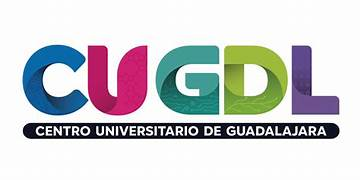

# Explica que es la aumentacion de datos coloca una imagen que lo ejemplifique y menciona cuales son las ventajas de aplicarlo en tu proyecto

[Aumento de datos con Ultralytics YOLO](https://docs.ultralytics.com/es/guides/yolo-data-augmentation)

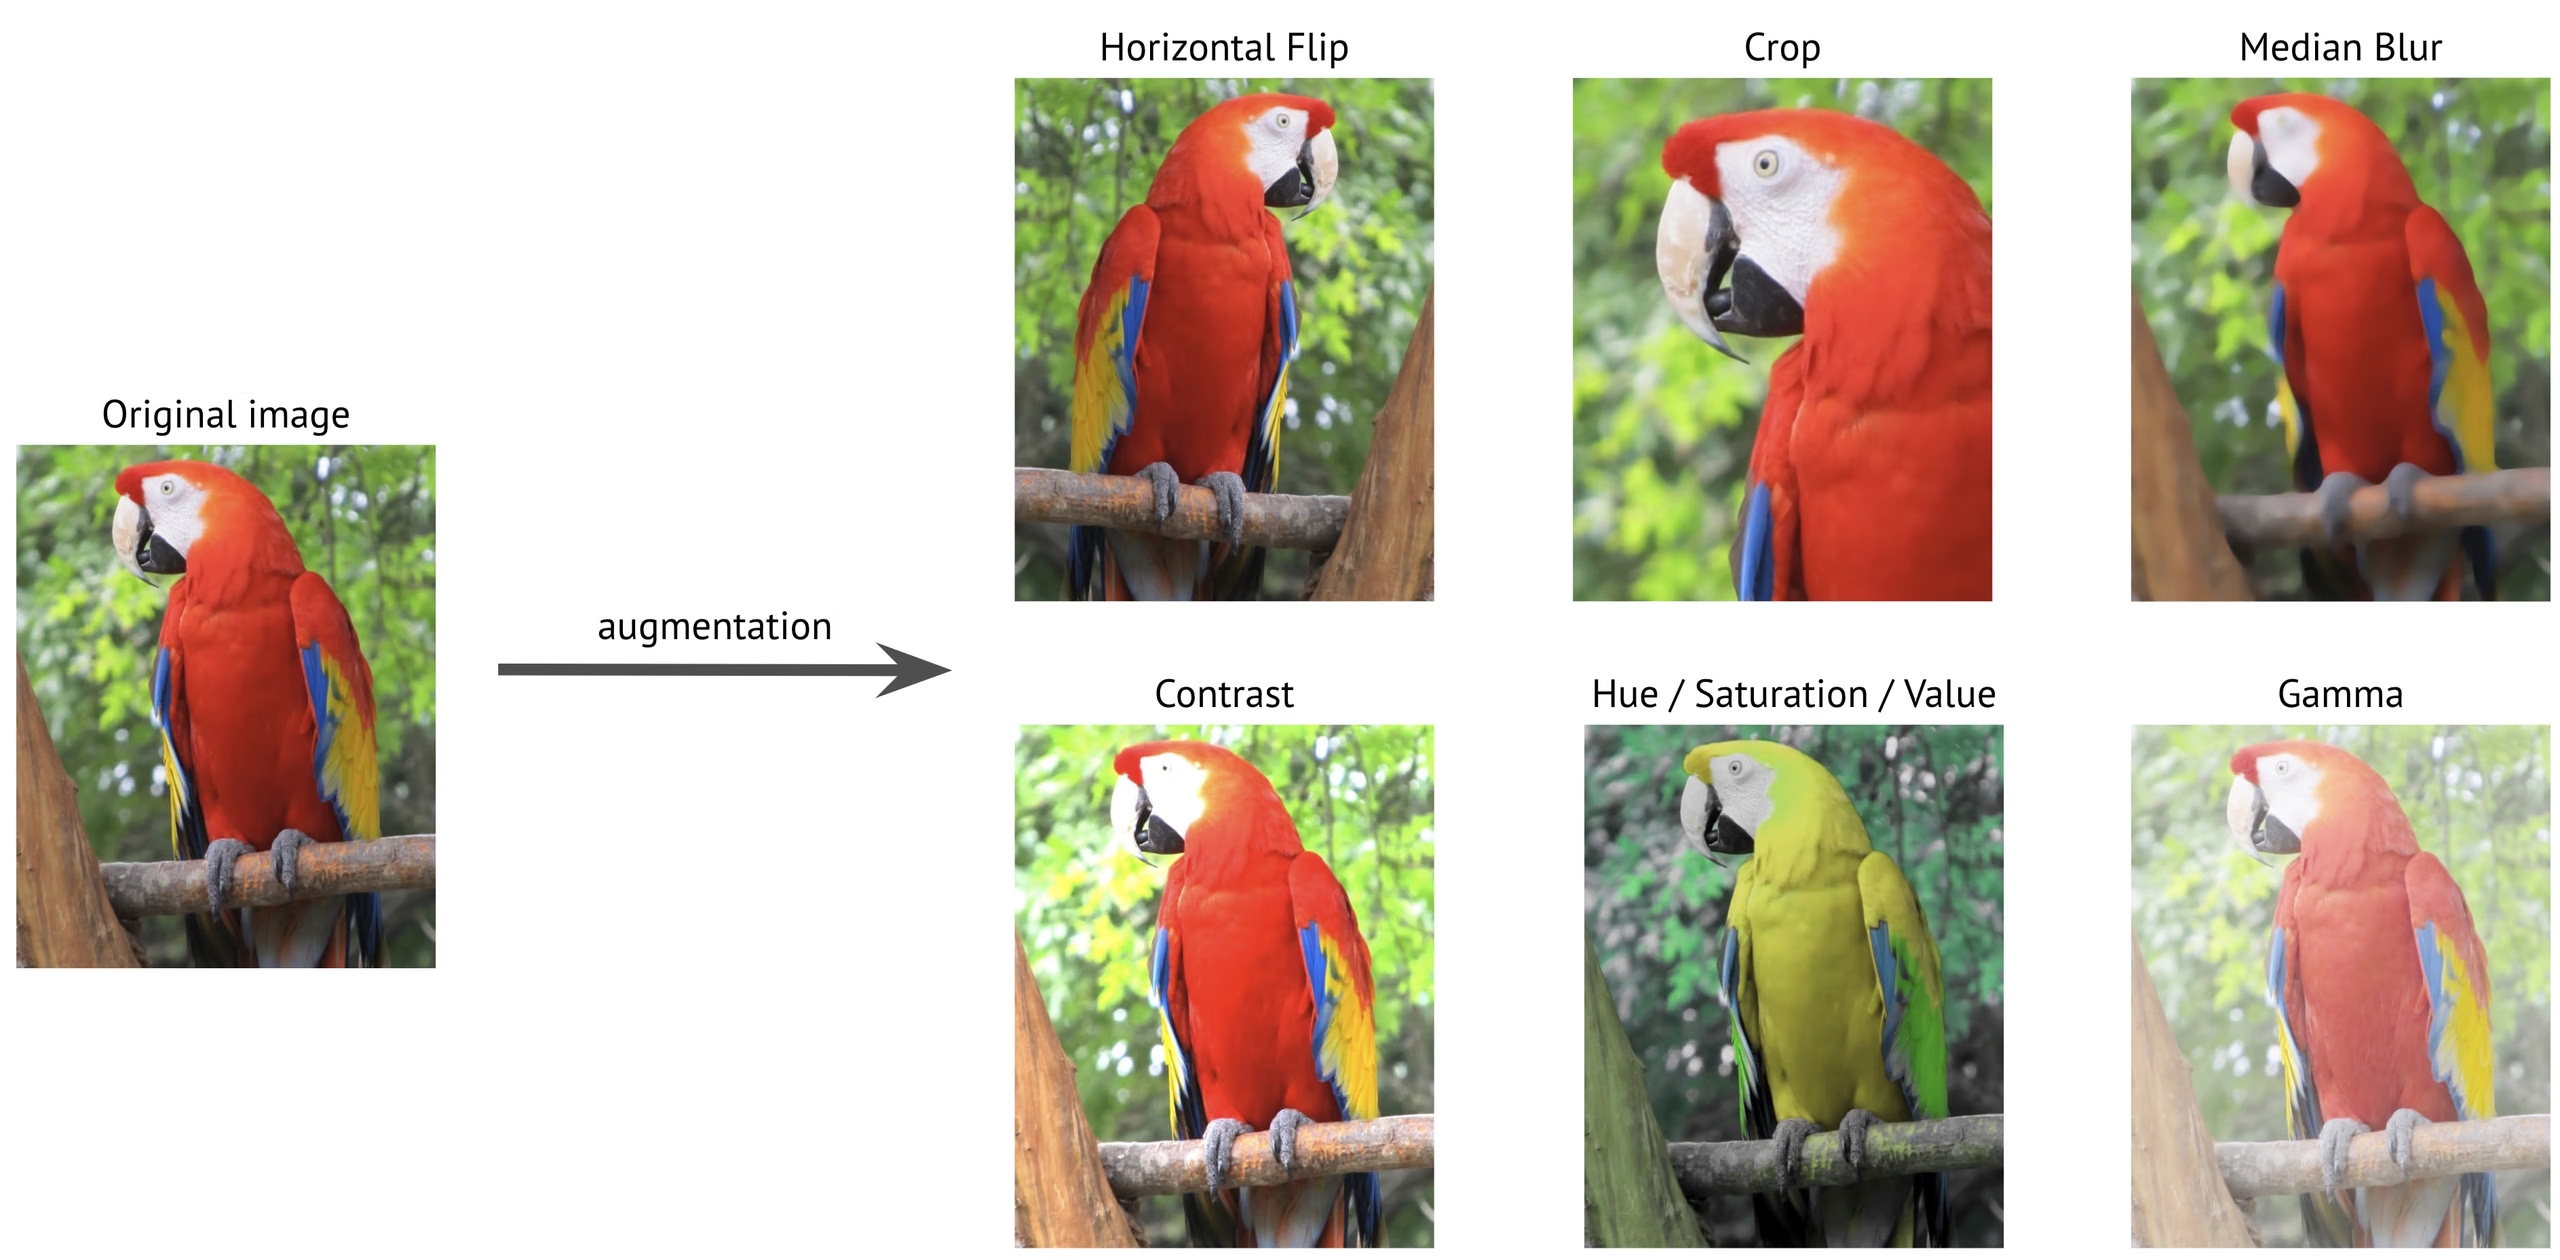

¿cGAN o aumento clásico? Datos sintéticos con pocos datos reales?
Si solo tengo 50 imágenes etiquetadas por clase, ¿vale la pena entrenar una GAN condicional para generar más datos, o basta con el aumento de datos clásico (volteos, rotaciones, traslaciones)?

Con las 60 000 imágenes de FashionMNIST cualquier CNN supera el 90 % y no se nota ninguna diferencia. Con 500 imágenes (50 por clase) el problema se vuelve real y medible.

Las tres reglas de un experimento honesto
Sin fuga: la cGAN solo ve las mismas 500 imágenes que el clasificador.
Mismo presupuesto: todos los clasificadores tienen la misma arquitectura y el mismo número de pasos de entrenamiento (no de épocas: con más imágenes habría más pasos y la comparación sería injusta).
Evaluación en reales y con varias semillas: siempre en las 10 000 imágenes reales de prueba, con 3 semillas, reportando media ± desviación.

## Librerías

In [7]:
import os, time, math, copy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import datasets
from torchvision.utils import make_grid
from scipy import linalg
from IPython.display import display
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE,
      "(" + torch.cuda.get_device_name(0) + ")" if DEVICE.type == "cuda" else "← activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → T4")

def fijar_semilla(s=0):
    torch.manual_seed(s); np.random.seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def mostrar_grid(x, titulo="", nrow=10, tam=(8, 8)):
    """x en [-1, 1], forma (N, C, H, W)."""
    g = make_grid(x.detach().cpu()[: nrow * nrow], nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=tam); plt.imshow(g.permute(1, 2, 0).numpy(), cmap="gray"); plt.axis("off"); plt.title(titulo); plt.show()

PyTorch 2.14.1+cu130 | dispositivo: cuda (Tesla T4)


In [8]:
NOMBRES_CLASES = {
    "FashionMNIST": ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "tenis", "bolsa", "botín"],
    "MNIST": [str(i) for i in range(10)],
    "CIFAR10": ["avión", "auto", "pájaro", "gato", "venado", "perro", "rana", "caballo", "barco", "camión"],
}

def cargar_tensor(nombre="FashionMNIST", split="train"):
    """Descarga el dataset y lo deja COMPLETO en memoria como tensor (N, C, 32, 32) en [-1, 1].
    Tenerlo en la GPU evita el DataLoader y acelera muchísimo el entrenamiento de GANs pequeñas."""
    clase = getattr(datasets, nombre)
    ds = clase("datos", train=(split == "train"), download=True)
    x = torch.as_tensor(np.asarray(ds.data))
    y = torch.as_tensor(np.asarray(ds.targets)).long()
    if x.ndim == 3:                          # escala de grises 28x28 → (N, 1, 32, 32) con relleno de 2 px
        x = F.pad(x.unsqueeze(1), (2, 2, 2, 2))
    else:                                    # CIFAR10 viene como (N, 32, 32, 3)
        x = x.permute(0, 3, 1, 2)
    x = x.float().div(255).mul(2).sub(1)    # [0, 255] → [-1, 1] (coincide con la tanh del generador)
    return x.to(DEVICE), y.to(DEVICE)

def lotes(x, y, batch, mezclar=True):
    idx = torch.randperm(len(x), device=x.device) if mezclar else torch.arange(len(x), device=x.device)
    for i in range(0, len(x) - batch + 1, batch):   # se descarta el último lote incompleto (BN lo agradece)
        j = idx[i:i + batch]
        yield x[j], y[j]

In [9]:
def _bn(n, usar):            # BatchNorm o "nada", para poder hacer ablaciones
    return nn.BatchNorm2d(n) if usar else nn.Identity()

class Generador(nn.Module):
    """DCGAN para 32x32: z (nz) → 4x4 → 8x8 → 16x16 → 32x32. Sin capas densas, solo convoluciones transpuestas."""
    def __init__(self, nz=100, ngf=64, canales=1, bn=True):
        super().__init__()
        b = not bn            # si hay BN el sesgo es redundante
        self.red = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 4, 4, 1, 0, bias=b), _bn(ngf * 4, bn), nn.ReLU(True),       # 4x4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=b), _bn(ngf * 2, bn), nn.ReLU(True),  # 8x8
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=b), _bn(ngf, bn), nn.ReLU(True),          # 16x16
            nn.ConvTranspose2d(ngf, canales, 4, 2, 1, bias=True), nn.Tanh(),                        # 32x32 en [-1, 1]
        )
    def forward(self, z):
        return self.red(z.view(z.size(0), -1, 1, 1))

class Discriminador(nn.Module):
    """Espejo del generador: convoluciones con stride 2 en lugar de pooling, LeakyReLU, y un LOGIT final.
    No ponemos Sigmoid: usamos BCEWithLogitsLoss, que es numéricamente estable."""
    def __init__(self, ndf=64, canales=1, bn=True):
        super().__init__()
        b = not bn
        self.red = nn.Sequential(
            nn.Conv2d(canales, ndf, 4, 2, 1, bias=True), nn.LeakyReLU(0.2, True),                  # 16x16 (sin BN en la 1a capa)
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=b), _bn(ndf * 2, bn), nn.LeakyReLU(0.2, True),    # 8x8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=b), _bn(ndf * 4, bn), nn.LeakyReLU(0.2, True),# 4x4
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=True),                                             # 1x1 → logit
        )
    def forward(self, x):
        return self.red(x).view(-1)

def init_dcgan(m):
    """Inicialización del artículo DCGAN (Radford et al., 2016): pesos ~ N(0, 0.02); BN: γ ~ N(1, 0.02), β = 0."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

def contar_parametros(m):
    return sum(p.numel() for p in m.parameters())

In [10]:
class GeneradorCond(nn.Module):
    """cGAN (Mirza y Osindero, 2014) con arquitectura DCGAN.
    La etiqueta y entra como un embedding aprendido que se CONCATENA al ruido z."""
    def __init__(self, nz=100, n_clases=10, dim_emb=50, ngf=64, canales=1):
        super().__init__()
        self.emb = nn.Embedding(n_clases, dim_emb)
        self.g = Generador(nz + dim_emb, ngf, canales, bn=True)
    def forward(self, z, y):
        return self.g(torch.cat([z, self.emb(y)], dim=1))

class DiscriminadorCond(nn.Module):
    """La etiqueta se convierte en un 'mapa' de 32x32 y se añade como canal extra a la imagen:
    D '¿es una imagen real DE ESTA CLASE?'."""
    def __init__(self, n_clases=10, ndf=64, canales=1, lado=32):
        super().__init__()
        self.lado = lado
        self.emb = nn.Embedding(n_clases, lado * lado)
        self.d = Discriminador(ndf, canales + 1, bn=True)
    def forward(self, x, y):
        mapa = self.emb(y).view(-1, 1, self.lado, self.lado)
        return self.d(torch.cat([x, mapa], dim=1))

In [11]:
class Juez(nn.Module):
    """CNN pequeña entrenada con datos REALES. Nos sirve de 'evaluador externo' de las imágenes generadas:
    (1) qué clase cree que es cada muestra → cobertura de modos; (2) sus características de 128-d → FID de dominio."""
    def __init__(self, canales=1, n_clases=10):
        super().__init__()
        self.cuerpo = nn.Sequential(
            nn.Conv2d(canales, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),        # 8
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten())
        self.cabeza = nn.Linear(128, n_clases)
    def forward(self, x): return self.cabeza(self.cuerpo(x))
    @torch.no_grad()
    def caracteristicas(self, x, lote=500):
        self.eval(); return torch.cat([self.cuerpo(x[i:i + lote]) for i in range(0, len(x), lote)])
    @torch.no_grad()
    def probabilidades(self, x, lote=500):
        self.eval(); return torch.cat([F.softmax(self(x[i:i + lote]), 1) for i in range(0, len(x), lote)])

def entrenar_juez(x, y, x_te, y_te, epocas=3, batch=256, aumento=False, semilla=0, verbose=True):
    fijar_semilla(semilla)
    m = Juez(x.shape[1], int(y.max()) + 1).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epocas):
        m.train()
        for xb, yb in lotes(x, y, min(batch, len(x))):
            if aumento:   # aumento "clásico": desplazamientos aleatorios de ±2 px y espejo horizontal
                xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
                if np.random.rand() < 0.5: xb = xb.flip(3)
            loss = F.cross_entropy(m(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
    acc = (m.probabilidades(x_te).argmax(1) == y_te).float().mean().item()
    if verbose: print(f"Juez: exactitud en prueba real = {acc:.3f}")
    return m, acc

In [12]:
def estadisticos(feats):
    f = feats.double().cpu().numpy()
    return f.mean(0), np.cov(f, rowvar=False)

def distancia_frechet(mu1, s1, mu2, s2):
    """FID = ||μ1 − μ2||² + Tr(Σ1 + Σ2 − 2 (Σ1 Σ2)^{1/2})   (Heusel et al., 2017)"""
    diff = mu1 - mu2
    covmean = linalg.sqrtm(s1 @ s2)
    if not np.isfinite(covmean).all():          # estabilización numérica recomendada en la implementación oficial
        eps = np.eye(len(s1)) * 1e-6
        covmean = linalg.sqrtm((s1 + eps) @ (s2 + eps))
    covmean = np.real(covmean)
    return float(diff @ diff + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

def fid_dominio(juez, x_a, x_b):
    """FID calculado con las características del JUEZ (128-d)"""
    return distancia_frechet(*estadisticos(juez.caracteristicas(x_a)), *estadisticos(juez.caracteristicas(x_b)))

In [13]:
DATASET = "FashionMNIST"
X_tr, Y_tr = cargar_tensor(DATASET, "train"); X_te, Y_te = cargar_tensor(DATASET, "test")
CLASES = NOMBRES_CLASES[DATASET]; CANALES = X_tr.shape[1]; N_CLASES = len(CLASES)

RUTA_JUEZ = f"juez_{DATASET}.pt"     # sube el del jueves 29 con: from google.colab import files; files.upload()
if os.path.exists(RUTA_JUEZ):
    juez = Juez(CANALES).to(DEVICE); juez.load_state_dict(torch.load(RUTA_JUEZ, map_location=DEVICE)); juez.eval()
    print("Juez cargado · exactitud en prueba:", round((juez.probabilidades(X_te).argmax(1) == Y_te).float().mean().item(), 3))
else:
    juez, _ = entrenar_juez(X_tr, Y_tr, X_te, Y_te, epocas=3); torch.save(juez.state_dict(), RUTA_JUEZ)

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 174kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.15MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.3MB/s]


Juez: exactitud en prueba real = 0.766


## Parte

DCGAN (pérdida no saturante, BCE con logits, *label smoothing*, inicialización N(0, 0.02), Adam 2·10⁻⁴ y β₁ = 0.5). Cambia lo que entra a cada red:

* **G(z, y)**: el *embedding* de la etiqueta se concatena al ruido.
* **D(x, y)**: la etiqueta entra como canal extra. Para los lotes falsos usamos **etiquetas aleatorias** uniformes, de modo que G practica todas las clases por igual.

Añadimos dos opciones útiles cuando hay **pocos datos**: ruido de instancia y un **aumento diferenciable** (desplazamiento y espejo aplicados **por igual** a reales y falsas antes de D, en el espíritu de *DiffAugment*, Zhao et al., 2020) para que D no memorice el conjunto pequeño.

El entrenamiento se mide en **iteraciones** (no épocas) para poder comparar un dataset de 60 000 imágenes con uno de 500.

In [14]:
def aumento_diferenciable(x, activo):
    if not activo: return x
    dx, dy = np.random.randint(-3, 4, size=2)
    x = torch.roll(x, shifts=(int(dx), int(dy)), dims=(2, 3))
    return x.flip(3) if np.random.rand() < 0.5 else x

@torch.no_grad()
def muestras_cond(G, n_por_clase=100, nz=100, semilla=0):
    g = torch.Generator(device=DEVICE).manual_seed(semilla)
    y = torch.arange(N_CLASES, device=DEVICE).repeat_interleave(n_por_clase)
    z = torch.randn(len(y), nz, device=DEVICE, generator=g)
    G.eval(); x = torch.cat([G(z[i:i + 500], y[i:i + 500]) for i in range(0, len(y), 500)]); G.train()
    return x, y

@torch.no_grad()
def evaluar_cgan(G, nz=100, n_por_clase=200):
    x, y = muestras_cond(G, n_por_clase, nz, semilla=123)
    pred = juez.probabilidades(x).argmax(1)
    return dict(acc_condicional=round((pred == y).float().mean().item(), 3),
                fid_dominio=round(fid_dominio(juez, X_te[:len(x)], x), 2))

def entrenar_cgan(x, y, iteraciones=4000, batch=128, nz=100, suavizado=0.9, ruido_instancia=0.0,
                  aumento_D=False, semilla=0, cada=500, nombre="cgan"):
    fijar_semilla(semilla)
    G = GeneradorCond(nz, N_CLASES, 50, 64, CANALES).to(DEVICE)
    D = DiscriminadorCond(N_CLASES, 64, CANALES).to(DEVICE)
    G.apply(init_dcgan); D.apply(init_dcgan)
    oG = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
    oD = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    batch = min(batch, len(x)); flujo = iter(()); hist, t0 = [], time.time()
    for it in range(1, iteraciones + 1):
        try: xr, yr = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xr, yr = next(flujo)
        b = len(xr); sigma = ruido_instancia * (1 - it / iteraciones)
        rd = (lambda t: aumento_diferenciable(t + sigma * torch.randn_like(t), aumento_D)) if sigma > 0 else (lambda t: aumento_diferenciable(t, aumento_D))
        # (1) D: real de su clase → suavizado ; falsa con etiqueta aleatoria → 0
        yf = torch.randint(0, N_CLASES, (b,), device=DEVICE)
        with torch.no_grad(): xf = G(torch.randn(b, nz, device=DEVICE), yf)
        o_r, o_f = D(rd(xr), yr), D(rd(xf), yf)
        lD = bce(o_r, torch.full_like(o_r, suavizado)) + bce(o_f, torch.zeros_like(o_f))
        oD.zero_grad(); lD.backward(); oD.step()
        # (2) G: no saturante
        yg = torch.randint(0, N_CLASES, (b,), device=DEVICE)
        o_g = D(rd(G(torch.randn(b, nz, device=DEVICE), yg)), yg)
        lG = bce(o_g, torch.ones_like(o_g))
        oG.zero_grad(); lG.backward(); oG.step()
        if it % cada == 0 or it == iteraciones:
            ev = evaluar_cgan(G, nz)
            hist.append(dict(iteracion=it, loss_D=lD.item(), loss_G=lG.item(), D_x=torch.sigmoid(o_r).mean().item(),
                             D_Gz=torch.sigmoid(o_f).mean().item(), **ev))
            print(f"[{nombre}] it {it:>5}/{iteraciones}  loss_D {lD.item():.3f}  loss_G {lG.item():.3f}  "
                  f"acc_cond {ev['acc_condicional']:.3f}  FID-d {ev['fid_dominio']:.1f}  ({time.time() - t0:.0f} s)")
    return G, pd.DataFrame(hist)

ITER_COMPLETO = 4000      # ≈ 8.5 épocas de FashionMNIST con lotes de 128
G_completo, h_completo = entrenar_cgan(X_tr, Y_tr, ITER_COMPLETO, nombre="cGAN-60k")

[cGAN-60k] it   500/4000  loss_D 0.907  loss_G 1.842  acc_cond 0.476  FID-d 9.1  (27 s)
[cGAN-60k] it  1000/4000  loss_D 0.876  loss_G 2.094  acc_cond 0.423  FID-d 9.7  (54 s)
[cGAN-60k] it  1500/4000  loss_D 1.014  loss_G 1.715  acc_cond 0.679  FID-d 3.6  (83 s)
[cGAN-60k] it  2000/4000  loss_D 1.095  loss_G 2.007  acc_cond 0.655  FID-d 2.7  (113 s)
[cGAN-60k] it  2500/4000  loss_D 1.044  loss_G 1.136  acc_cond 0.615  FID-d 2.0  (143 s)
[cGAN-60k] it  3000/4000  loss_D 1.058  loss_G 1.397  acc_cond 0.695  FID-d 1.0  (173 s)
[cGAN-60k] it  3500/4000  loss_D 1.031  loss_G 1.206  acc_cond 0.684  FID-d 1.6  (203 s)
[cGAN-60k] it  4000/4000  loss_D 1.149  loss_G 1.380  acc_cond 0.759  FID-d 0.8  (233 s)


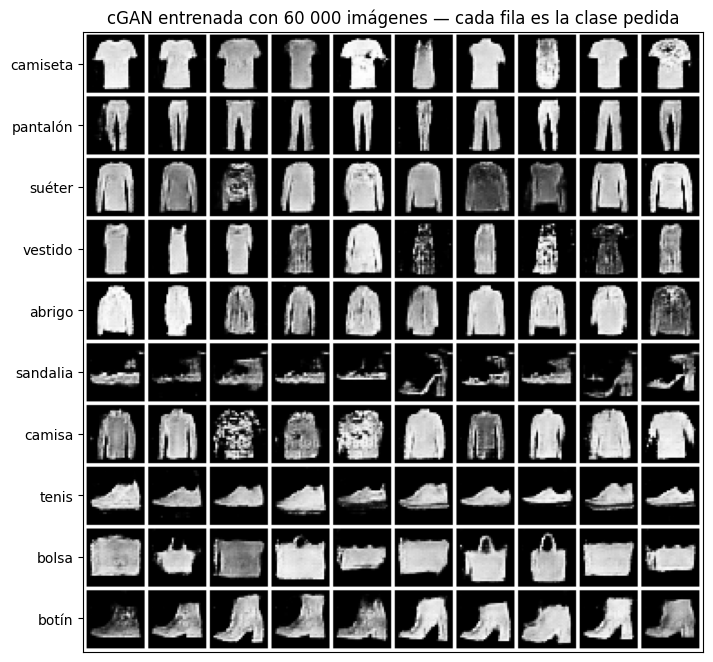

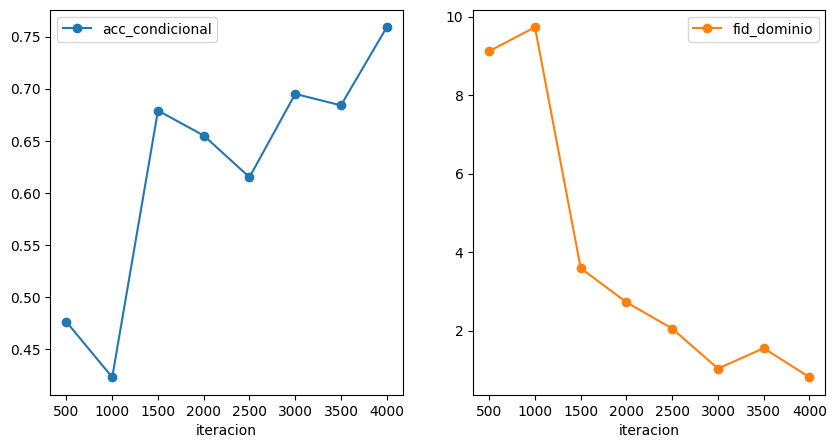

In [15]:
def rejilla_por_clase(G, titulo, nz=100):
    x, _ = muestras_cond(G, n_por_clase=10, nz=nz, semilla=7)
    g = make_grid(x.cpu(), nrow=10, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=(8, 8.4)); plt.imshow(g.permute(1, 2, 0)); plt.title(titulo)
    plt.yticks([17 + 34 * i for i in range(N_CLASES)], CLASES); plt.xticks([]); plt.show()

rejilla_por_clase(G_completo, "cGAN entrenada con 60 000 imágenes — cada fila es la clase pedida")
h_completo.plot(x="iteracion", y=["acc_condicional", "fid_dominio"], subplots=True, marker="o", figsize=(10, 5), layout=(1, 2)); plt.show()

Inspección visual ¿todas las filas corresponden a la clase pedida? si

¿Hay diversidad de cada fila (colores, formas, poses) o se repite la misma prenda? No hay mucha diversidad pero sí son prendas diferentes.

## Parte B

Dos preguntas distintas, dos métricas:
* **¿Genera lo que se le pide?** → *exactitud condicional*: el juez clasifica las muestras de la clase *c* y medimos cuántas reconoce como *c*.
* **¿Se parece a la distribución real de esa clase?** → **FID de dominio por clase**: 1000 generadas de la clase *c* vs. las 1000 reales de prueba de esa clase.

,clase,acc_condicional,fid_dominio
0,camiseta,0.514,0.697
1,pantalón,0.954,0.856
2,suéter,0.132,0.732
3,vestido,0.682,1.032
4,abrigo,0.973,1.165
5,sandalia,0.983,3.617
6,camisa,0.529,2.032
7,tenis,0.935,0.688
8,bolsa,0.916,1.618
9,botín,0.979,1.154


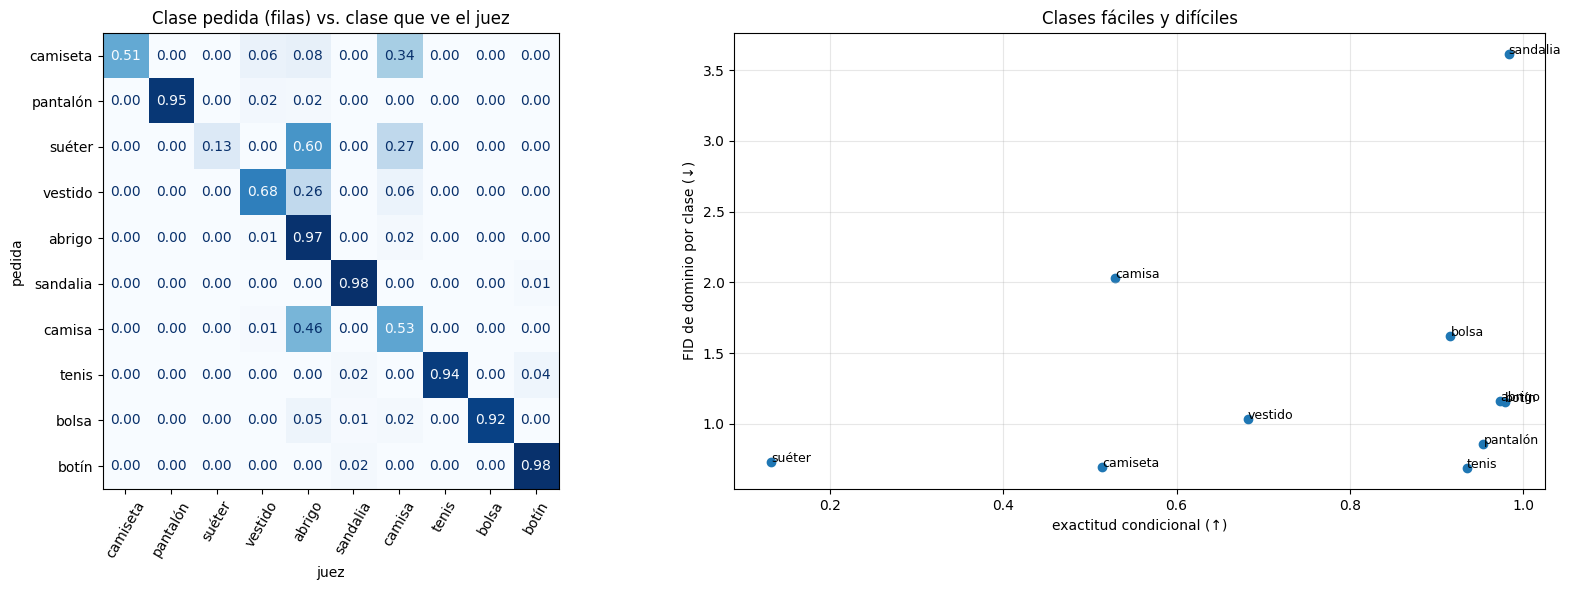

In [16]:
@torch.no_grad()
def evaluacion_por_clase(G, nz=100, n=1000):
    x, y = muestras_cond(G, n, nz, semilla=99)
    pred = juez.probabilidades(x).argmax(1)
    filas = []
    for c in range(N_CLASES):
        xc = x[y == c]; xr = X_te[Y_te == c][:n]
        filas.append(dict(clase=CLASES[c], acc_condicional=(pred[y == c] == c).float().mean().item(),
                          fid_dominio=fid_dominio(juez, xr, xc)))
    return pd.DataFrame(filas), y.cpu(), pred.cpu()

tabla_clase, y_ped, y_pred = evaluacion_por_clase(G_completo)
display(tabla_clase.round(3))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
ConfusionMatrixDisplay(confusion_matrix(y_ped, y_pred, normalize="true"), display_labels=CLASES).plot(
    ax=ax[0], cmap="Blues", values_format=".2f", colorbar=False)
ax[0].set(title="Clase pedida (filas) vs. clase que ve el juez", xlabel="juez", ylabel="pedida"); ax[0].tick_params(axis="x", rotation=60)
ax[1].scatter(tabla_clase.acc_condicional, tabla_clase.fid_dominio)
for _, f in tabla_clase.iterrows(): ax[1].annotate(f.clase, (f.acc_condicional, f.fid_dominio), fontsize=9)
ax[1].set(xlabel="exactitud condicional (↑)", ylabel="FID de dominio por clase (↓)", title="Clases fáciles y difíciles"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("cgan_evaluacion_por_clase.png", dpi=110); plt.show()

¿Qué clases confunde más la cGAN? Suéter, solo se clasifica correctamente un 13% de las veces

¿Coinciden con las que confunde un clasificador normal (p. ej., camisa/camiseta/suéter/abrigo)? si

¿Es un problema del generador, del juez, o de los datos? de los datos y del generador

## Parte C

¿Ayudan los datos sintéticos cuando hay pocos reales? si



**Escenario.** Solo tenemos `N_POR_CLASE` imágenes reales etiquetadas por clase. Comparamos:

| Clave | Datos de entrenamiento del clasificador | Protocolo |
|---|---|---|
| `R` | Solo las imágenes reales limitadas | TRTR (referencia) |
| `R+aum` | Reales limitadas + aumento clásico (desplazamiento ±2 px, espejo) | TRTR con aumento |
| `S_honesta` | Solo sintéticas de una cGAN entrenada **con las mismas imágenes limitadas** | TSTR |
| `R+S_honesta` | Reales limitadas + sintéticas honestas | TRSTR |
| `R+S_fuga` ⚠️ | Reales limitadas + sintéticas de la cGAN de la Parte A (vio **60 000** imágenes) | **No válido como resultado:** cota con fuga de información |
| `R_60k` | Las 60 000 reales | Techo de referencia |

Datos limitados: 500 imágenes reales (50 por clase)


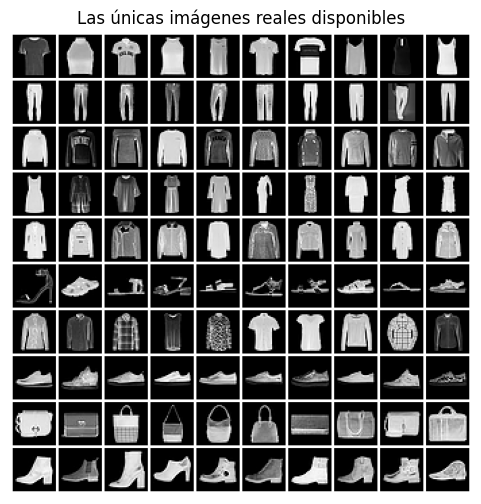

In [17]:
N_POR_CLASE = 50          # probar 20, 50 o 200
SINT_POR_CLASE = 500      # imágenes sintéticas por clase
PASOS_CLF = 800           # mismo presupuesto de entrenamiento para todos los clasificadores
SEMILLAS = [0, 1, 2]

def subconjunto_limitado(n, semilla=0):
    g = torch.Generator(device="cpu").manual_seed(semilla)
    idx = torch.cat([torch.nonzero(Y_tr.cpu() == c).view(-1)[torch.randperm(int((Y_tr == c).sum()), generator=g)[:n]]
                     for c in range(N_CLASES)])
    return X_tr[idx.to(DEVICE)], Y_tr[idx.to(DEVICE)]

def entrenar_clasificador(x, y, pasos=PASOS_CLF, batch=64, aumento=False, semilla=0):
    """Mismo clasificador para todas las condiciones; número de PASOS fijo (no de épocas)."""
    fijar_semilla(semilla)
    m = Juez(CANALES, N_CLASES).to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
    flujo = iter(()); batch = min(batch, len(x))
    for _ in range(pasos):
        try: xb, yb = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xb, yb = next(flujo)
        if aumento:
            xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
            if np.random.rand() < 0.5: xb = xb.flip(3)
        m.train(); loss = F.cross_entropy(m(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
    pred = m.probabilidades(X_te).argmax(1)
    return (pred == Y_te).float().mean().item(), pred

X_lim, Y_lim = subconjunto_limitado(N_POR_CLASE)
print(f"Datos limitados: {len(X_lim)} imágenes reales ({N_POR_CLASE} por clase)")
mostrar_grid(X_lim[torch.argsort(Y_lim)][:: max(1, N_POR_CLASE // 10)][:100], "Las únicas imágenes reales disponibles", tam=(6, 6))

### C.1 La cGAN2
Con tan pocos datos D puede **memorizar** el conjunto real y dejar de dar señal útil. Por eso activamos el aumento diferenciable y el ruido de instancia.

[cGAN-500] it   500/3000  loss_D 1.584  loss_G 0.768  acc_cond 0.444  FID-d 10.3  (13 s)
[cGAN-500] it  1000/3000  loss_D 1.063  loss_G 0.878  acc_cond 0.269  FID-d 12.3  (26 s)
[cGAN-500] it  1500/3000  loss_D 1.052  loss_G 0.994  acc_cond 0.598  FID-d 7.4  (38 s)
[cGAN-500] it  2000/3000  loss_D 1.498  loss_G 1.346  acc_cond 0.499  FID-d 8.5  (51 s)
[cGAN-500] it  2500/3000  loss_D 1.648  loss_G 0.797  acc_cond 0.338  FID-d 12.2  (64 s)
[cGAN-500] it  3000/3000  loss_D 1.307  loss_G 1.515  acc_cond 0.439  FID-d 6.7  (77 s)


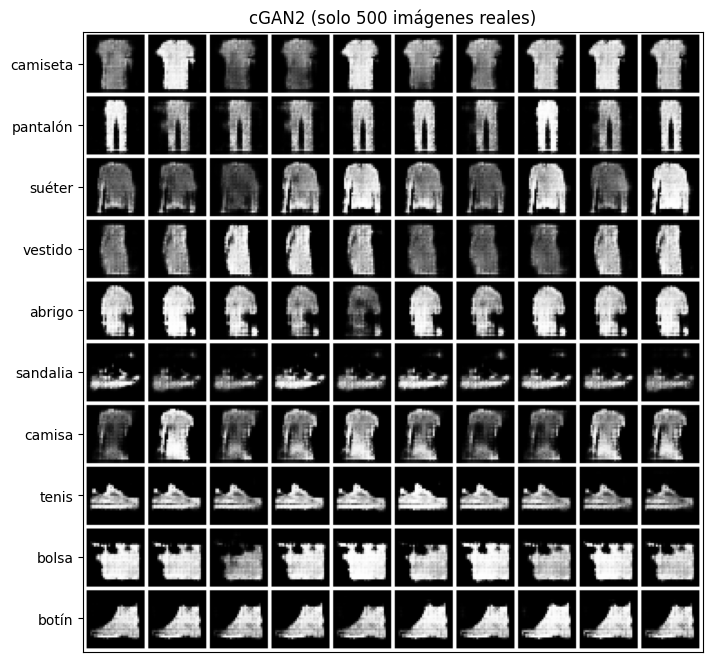

In [18]:
ITER_LIMITADO = 3000
G_honesta, h_honesta = entrenar_cgan(X_lim, Y_lim, ITER_LIMITADO, batch=64, ruido_instancia=0.1, aumento_D=True,
                                     nombre=f"cGAN-{len(X_lim)}")
rejilla_por_clase(G_honesta, f"cGAN2 (solo {len(X_lim)} imágenes reales)")

Entrena otra cGAN2 **sin** `aumento_D` ni ruido (`ruido_instancia=0.0, aumento_D=False`). Compara rejilla, exactitud condicional y FID. ¿Qué le pasa a D con 500 imágenes sin aumento?

In [19]:
# ✍️ TU TURNO C.1

R              n=   500  exactitud = 0.787
R+aum          n=   500  exactitud = 0.661
S_honesta      n=  5000  exactitud = 0.451
R+S_honesta    n=  5500  exactitud = 0.696
R+S_fuga ⚠️    n=  5500  exactitud = 0.627
R_60k          n= 60000  exactitud = 0.783


,mean,std
condicion,,
R,0.7874,0.0037
R+aum,0.6608,0.0811
S_honesta,0.4513,0.0146
R+S_honesta,0.6963,0.0233
R+S_fuga ⚠️,0.6267,0.0938
R_60k,0.7829,0.0059


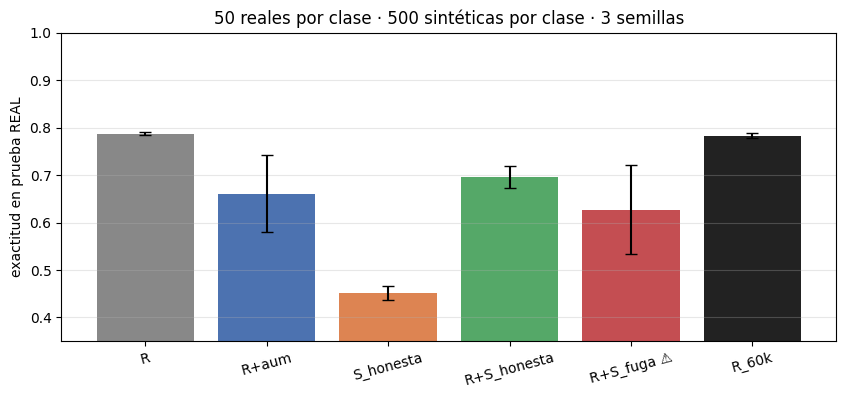

In [20]:
X_sh, Y_sh = muestras_cond(G_honesta, SINT_POR_CLASE, semilla=1)     # sintéticas honestas
X_sf, Y_sf = muestras_cond(G_completo, SINT_POR_CLASE, semilla=1)    # sintéticas con fuga

CONDICIONES = {
    "R":            lambda: (X_lim, Y_lim, False),
    "R+aum":        lambda: (X_lim, Y_lim, True),
    "S_honesta":    lambda: (X_sh, Y_sh, False),
    "R+S_honesta":  lambda: (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), False),
    "R+S_fuga ⚠️":  lambda: (torch.cat([X_lim, X_sf]), torch.cat([Y_lim, Y_sf]), False),
    "R_60k":        lambda: (X_tr, Y_tr, False),
}
filas, preds = [], {}
for nombre, datos in CONDICIONES.items():
    x, y, aum = datos()
    for s in SEMILLAS:
        acc, pred = entrenar_clasificador(x, y, aumento=aum, semilla=s)
        filas.append(dict(condicion=nombre, semilla=s, exactitud=acc, n_imagenes=len(x))); preds[(nombre, s)] = pred
    print(f"{nombre:<14s} n={len(x):>6}  exactitud = {np.mean([f['exactitud'] for f in filas if f['condicion'] == nombre]):.3f}")

res_aumento = pd.DataFrame(filas)
resumen_aum = res_aumento.groupby("condicion", sort=False).exactitud.agg(["mean", "std"]).round(4)
display(resumen_aum)
res_aumento.to_csv(f"aumento_sintetico_N{N_POR_CLASE}.csv", index=False)

plt.figure(figsize=(10, 4))
colores = ["#888", "#4c72b0", "#dd8452", "#55a868", "#c44e52", "#222"]
plt.bar(resumen_aum.index, resumen_aum["mean"], yerr=resumen_aum["std"], capsize=4, color=colores)
plt.ylim(max(0, resumen_aum["mean"].min() - 0.1), 1); plt.ylabel("exactitud en prueba REAL")
plt.title(f"{N_POR_CLASE} reales por clase · {SINT_POR_CLASE} sintéticas por clase · {len(SEMILLAS)} semillas")
plt.xticks(rotation=15); plt.grid(axis="y", alpha=.3); plt.savefig(f"aumento_sintetico_N{N_POR_CLASE}.png", dpi=110); plt.show()

In [21]:
# ¿En qué clases ayudaron (o dañaron) las sintéticas honestas? Diferencia de exactitud por clase vs. "R"
def acc_por_clase(nombre):
    return np.mean([[(preds[(nombre, s)][Y_te == c] == c).float().mean().item() for c in range(N_CLASES)] for s in SEMILLAS], axis=0)
dif = pd.DataFrame({"clase": CLASES,
                    "R": acc_por_clase("R"),
                    "Δ R+aum": acc_por_clase("R+aum") - acc_por_clase("R"),
                    "Δ R+S_honesta": acc_por_clase("R+S_honesta") - acc_por_clase("R")})
display(dif.round(3))

,clase,R,Δ R+aum,Δ R+S_honesta
0,camiseta,0.739,-0.300,-0.281
1,pantalón,0.926,-0.008,-0.073
2,suéter,0.734,-0.253,-0.042
3,vestido,0.772,-0.263,0.133
4,abrigo,0.589,-0.034,-0.219
5,sandalia,0.876,-0.088,0.011
6,camisa,0.504,-0.051,-0.110
7,tenis,0.927,-0.094,-0.295
8,bolsa,0.911,-0.143,-0.046
9,botín,0.895,-0.032,0.012


* Ordena las condiciones por exactitud.
R (500 reales): $0.7874 \pm 0.0037$

  - R_60k (dataset completo): $0.7829 \pm 0.0059$
  - R+S_honesta (reales + sintéticas honestas): $0.6963 \pm 0.0233$
  - R+aum (reales + aumento clásico): $0.6608 \pm 0.0811$
  - R+S_fuga (reales + sintéticas con fuga): $0.6267 \pm 0.0938$
  - S_honesta (solo sintéticas honestas): $0.4513 \pm 0.0146$

* ¿Ayudó la cGAN honesta
frente a `R`? ¿Ayudó frente a R? No, perjudicó el desempeño. La exactitud bajó de $0.7874$ (R) a $0.6963$ (R+S_honesta), una caída de $0.0911$ puntos ($9.11\%$). Esta diferencia es mucho mayor que la variación entre semillas ($\pm 0.0037$ y $\pm 0.0233$), por lo que el empeoramiento es estadísticamente significativo.
* ¿Y frente a `R+aum`? Sí, ligeramente en promedio y con mucha mayor estabilidad. R+S_honesta ($0.6963 \pm 0.0233$) supera a R+aum ($0.6608 \pm 0.0811$) por $+0.0355$ puntos. Sin embargo, dado que R+aum tiene una desviación estándar muy alta ($\pm 0.0811$)

Responde con **media ± desviación** y discute si la diferencia es mayor que la variación entre semillas.


* Explica con tus palabras por qué `R+S_fuga` **no** es un resultado válido aunque dé la mejor exactitud.  Porque existe fuga de datos (data leakage). El generador G_completo fue entrenado usando todo el conjunto de datos
* ¿En qué situación real se cometería este error sin darse cuenta? en proyectos aplicados cuando un equipo entrena primero un modelo generativo (GAN o Diffusion) utilizando toda la base de datos


* ¿Qué te dice `S_honesta` (TSTR) sobre la calidad de las sintéticas? Obtener $0.4513 \pm 0.0146$ de exactitud (frente a un $0.10$ de azar puro en 10 clases) indica que el generador logró capturar la estructura básica y las formas generales de las prendas a partir de apenas 50 imágenes reales por clase. Sin embargo, al estar muy por debajo del $0.7874$ de las imágenes reales (R), demuestra que las imágenes sintéticas carecen de la diversidad y los detalles finos necesarios para que un clasificador generalice bien por sí solo.
* ¿En qué clases la cGAN honesta ayudó o dañó más (tabla por clase)? Solo hubo grandes mejoras en vestido ($+0.133$), botín ($+0.012$) y sandalia ($+0.011$). Las caídas más fuertes ocurrieron en tenis ($-0.295$), camiseta ($-0.281$) y abrigo ($-0.219$), seguidas por camisa ($-0.110$) y pantalón ($-0.073$).

## Parte D

Prof asigna un equipo variación, la ejecuta (vuelve a correr la Parte C con el cambio) y la presenta en 2 minutos en clase + pregunta:

| Equipo | Variación | Pregunta |
|---|---|---|
| 1 | `N_POR_CLASE = 20` | ¿Con aún menos datos las sintéticas ayudan más o menos? |
| 2 | `N_POR_CLASE = 200` | ¿A partir de cuántos datos reales deja de valer la pena? |
| 3 | `SINT_POR_CLASE = 50` y `= 2000` | ¿Más sintéticas = mejor? ¿Hay saturación? |
| 4 | cGAN honesta sin aumento diferenciable | ¿Cuánto importa estabilizar la cGAN para que las sintéticas sirvan? |
| 5 | Combinar `R+aum` **y** sintéticas honestas | ¿Son complementarias las dos formas de aumento? |
| 6 | Filtrar sintéticas: conservar solo las que el juez clasifica con confianza > 0.9 en su clase | ¿Filtrar por calidad ayuda? (cuidado: ¿el juez vio datos que no debería?) |

# Parte E
Ejecuta con tus datos reales, compara 1 variación y grafica 16 imagenes generas por cGAN y por Aumentación

In [22]:
# Login using e.g. `huggingface-cli login` to access this dataset
from datasets import load_dataset, ClassLabel, Image as HFImage
import pandas as pd

ds = load_dataset("FatimaSaadNaik/indoor-scenes-dataset")
print(ds)

README.md:   0%|          | 0.00/401 [00:00<?, ?B/s]

data/train-00000-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  366MB            

data/train-00000-of-00006.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  418MB            

data/train-00001-of-00006.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  641MB            

... (5 outputs left out)

data/train-00005-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  384MB            

data/train-00005-of-00006.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15620 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'caption', 'file_name', 'category'],
        num_rows: 15620
    })
})


In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Seleccionar N_POR_CLASE = 50 datos reales por clase
N_POR_CLASE = 50
N_CLASES = 10
Z_DIM = 64

idx_lim = []
for c in range(N_CLASES):
    idx_c = (Y_tr_propio == c).nonzero(as_tuple=True)[0][:N_POR_CLASE]
    idx_lim.append(idx_c)
idx_lim = torch.cat(idx_lim)

X_lim_p = X_tr_propio[idx_lim]
Y_lim_p = Y_tr_propio[idx_lim]

# 2. Definir Generador (G_propia) y Discriminador condicionales
class GeneradorProp(nn.Module):
    def __init__(self, z_dim=64, n_clases=10):
        super().__init__()
        self.emb = nn.Embedding(n_clases, n_clases)
        self.net = nn.Sequential(
            nn.Linear(z_dim + n_clases, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(True),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(True),
            nn.Linear(512, 28 * 28),
            nn.Tanh()
        )
    def forward(self, z, y):
        x = torch.cat([z, self.emb(y)], dim=1)
        return self.net(x).view(-1, 1, 28, 28)

class DiscriminadorProp(nn.Module):
    def __init__(self, n_clases=10):
        super().__init__()
        self.emb = nn.Embedding(n_clases, n_clases)
        self.net = nn.Sequential(
            nn.Linear(28 * 28 + n_clases, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 1)
        )
    def forward(self, img, y):
        x = torch.cat([img.view(img.size(0), -1), self.emb(y)], dim=1)
        return self.net(x)

# 3. Entrenar G_propia con tus datos reales limitados
G_propia = GeneradorProp(Z_DIM, N_CLASES).to(device)
D_propia = DiscriminadorProp(N_CLASES).to(device)

opt_G = optim.Adam(G_propia.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = optim.Adam(D_propia.parameters(), lr=2e-4, betas=(0.5, 0.999))
criterion = nn.BCEWithLogitsLoss()

loader = DataLoader(TensorDataset(X_lim_p, Y_lim_p), batch_size=64, shuffle=True)

G_propia.train()
for epoch in range(80):
    for real_x, real_y in loader:
        real_x, real_y = real_x.to(device), real_y.to(device)
        bs = real_x.size(0)

        # Paso Discriminador
        opt_D.zero_grad()
        z = torch.randn(bs, Z_DIM, device=device)
        fake_x = G_propia(z, real_y)
        loss_D = criterion(D_propia(real_x, real_y), torch.ones(bs, 1, device=device)) + \
                 criterion(D_propia(fake_x.detach(), real_y), torch.zeros(bs, 1, device=device))
        loss_D.backward()
        opt_D.step()

        # Paso Generador
        opt_G.zero_grad()
        loss_G = criterion(D_propia(fake_x, real_y), torch.ones(bs, 1, device=device))
        loss_G.backward()
        opt_G.step()

G_propia.eval()

# 4. Función para generar muestras sintéticas
@torch.no_grad()
def muestras_cond_prop(G, n_por_clase, semilla=1):
    torch.manual_seed(semilla)
    ys = torch.arange(N_CLASES, device=device).repeat_interleave(n_por_clase)
    zs = torch.randn(len(ys), Z_DIM, device=device)
    imgs = G(zs, ys)
    return imgs.cpu(), ys.cpu()

print("¡G_propia entrenada con éxito!\n")

# 5. Comparar variaciones: R vs R+aum vs R+S_honesta
X_sh_p, Y_sh_p = muestras_cond_prop(G_propia, n_por_clase=200, semilla=1)

print("--- COMPARACIÓN DE VARIACIONES (DATOS PROPIOS) ---")
for nombre, x_tr, y_tr, aum in [
    ("R (500 reales)", X_lim_p, Y_lim_p, False),
    ("R+aum (aumento clásico)", X_lim_p, Y_lim_p, True),
    ("R+S_honesta (200 sint/clase)", torch.cat([X_lim_p, X_sh_p]), torch.cat([Y_lim_p, Y_sh_p]), False),
]:
    torch.manual_seed(42)
    clf = nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 256),
        nn.ReLU(),
        nn.Linear(256, N_CLASES)
    ).to(device)
    opt = optim.Adam(clf.parameters(), lr=1e-3)
    dl = DataLoader(TensorDataset(x_tr, y_tr), batch_size=64, shuffle=True)

    for _ in range(20):
        for bx, by in dl:
            bx, by = bx.to(device), by.to(device)
            if aum and torch.rand(1).item() < 0.5:
                bx = torch.flip(bx, dims=[3])
            opt.zero_grad()
            nn.CrossEntropyLoss()(clf(bx), by).backward()
            opt.step()

    with torch.no_grad():
        acc = (clf(X_te_propio.to(device)).argmax(1).cpu() == Y_te_propio).float().mean().item()
    print(f"{nombre:<30} -> Exactitud en prueba: {acc:.4f}")

¡G_propia entrenada con éxito!

--- COMPARACIÓN DE VARIACIONES (DATOS PROPIOS) ---
R (500 reales)                 -> Exactitud en prueba: 0.1567
R+aum (aumento clásico)        -> Exactitud en prueba: 0.1817
R+S_honesta (200 sint/clase)   -> Exactitud en prueba: 0.1533


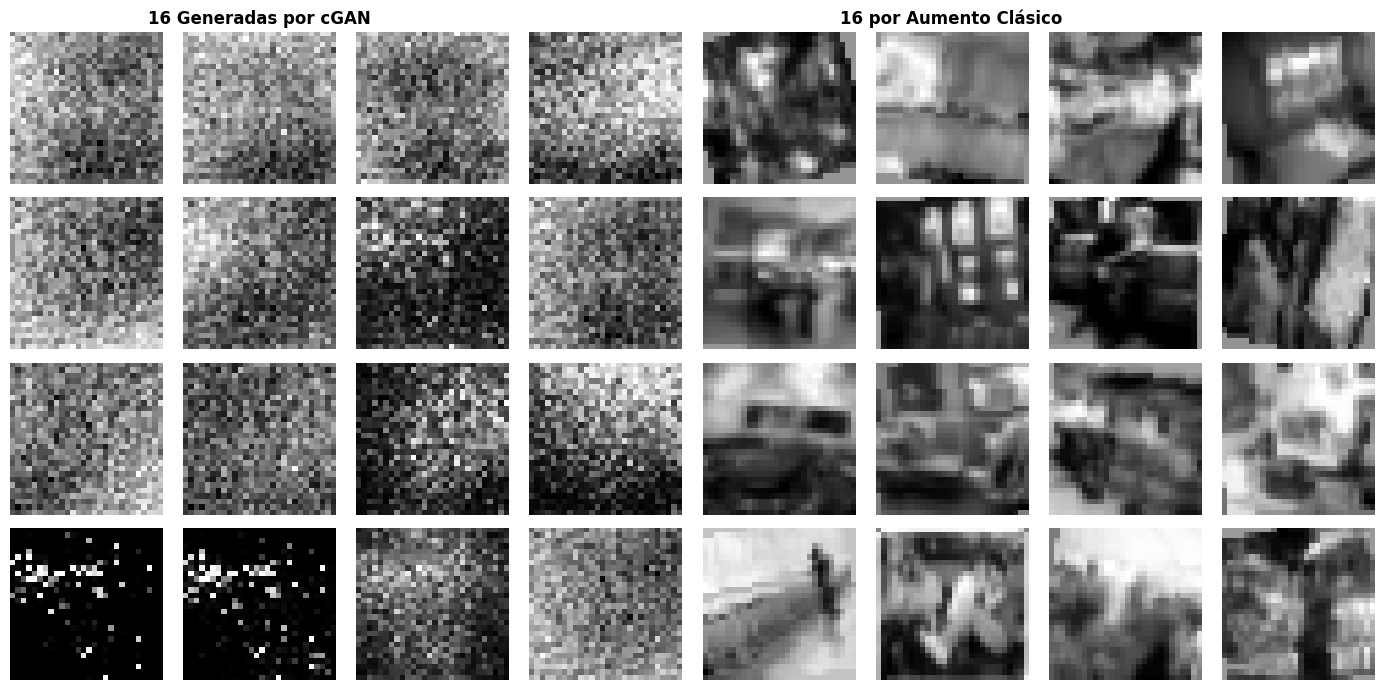

In [27]:
import matplotlib.pyplot as plt
from torchvision import transforms

# 1. Definir aumento clásico
transform_aum = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0))
])

# 2. Obtener 16 imágenes aumentadas a partir de tus datos reales
imgs_aum = torch.stack([transform_aum(X_tr_propio[i]) for i in range(16)])

# 3. Obtener 16 imágenes generadas por tu cGAN (G_propia)
imgs_cgan, labels_cgan = muestras_cond_prop(G_propia, n_por_clase=2, semilla=1)
imgs_cgan = imgs_cgan[:16]

# 4. Graficar comparativa 4x4 (izquierda) vs 4x4 (derecha)
fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for i in range(16):
    r, c = divmod(i, 4)

    # Izquierda (cols 0-3): Generadas por cGAN
    img_g = (imgs_cgan[i].cpu().squeeze() * 0.5 + 0.5).clamp(0, 1)
    axes[r, c].imshow(img_g, cmap="gray" if CANALES == 1 else None)
    axes[r, c].axis("off")
    if r == 0 and c == 1:
        axes[r, c].set_title("16 Generadas por cGAN", fontsize=12, fontweight="bold")

    # Derecha (cols 4-7): Aumento clásico
    img_a = (imgs_aum[i].cpu().squeeze() * 0.5 + 0.5).clamp(0, 1)
    axes[r, c + 4].imshow(img_a, cmap="gray" if CANALES == 1 else None)
    axes[r, c + 4].axis("off")
    if r == 0 and c == 1:
        axes[r, c + 4].set_title("16 por Aumento Clásico", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()